 02_visualization — charts from processed benchmark outputs

In [17]:
%pip install matplotlib --quiet

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)

ROOT = Path.cwd().resolve().parents[0] if Path.cwd().name == "notebooks" else Path.cwd().resolve()
RESULTS_DIR = ROOT / "results"
PROCESSED_DIR = RESULTS_DIR / "processed"
FIGURES_DIR = ROOT / "docs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

summary_path = PROCESSED_DIR / "summary.csv"
samples_path = PROCESSED_DIR / "samples.csv"
model_summary_path = PROCESSED_DIR / "model_summary.csv"
ranking_path = PROCESSED_DIR / "ranking.csv"

summary = pd.read_csv(summary_path)
samples = pd.read_csv(samples_path)
model_summary = pd.read_csv(model_summary_path)
ranking = pd.read_csv(ranking_path)

print("summary:", summary.shape)
print("samples:", samples.shape)
print("model_summary:", model_summary.shape)
print("ranking:", ranking.shape)


Note: you may need to restart the kernel to use updated packages.
summary: (15, 11)
samples: (12300, 28)
model_summary: (12, 10)
ranking: (3, 5)


 Quick inspection

In [18]:
display(summary.head())
display(model_summary.head())
display(ranking.head())


,model,run_id,dataset,accuracy,ttft,latency,tps,cpu,ram,tps_per_ram,accuracy_per_latency
0,gemma-3-1b-it-Q8_0,2026-03-31_10-52-54,mmlu,0.310,125.6957,316.5059,5.3356,65.7547,184.36,0.028941,0.000979
1,gemma-3-1b-it-Q8_0,2026-03-31_10-52-54,hellaswag,0.293,112.6663,304.7556,5.2812,66.1447,187.45,0.028174,0.000961
2,gemma-3-1b-it-Q8_0,2026-03-31_10-52-54,gsm8k,0.031,108.7212,770.5723,3.4579,74.4935,189.75,0.018223,0.000040
3,gemma-3-1b-it-Q8_0,2026-03-31_15-37-23,mmlu,0.310,125.7233,315.9056,5.3528,66.1230,184.25,0.029052,0.000981
4,gemma-3-1b-it-Q8_0,2026-03-31_15-37-23,hellaswag,0.293,112.1800,303.2874,5.3019,65.7051,177.03,0.029949,0.000966


,model,dataset,accuracy,ttft,latency,tps,cpu,ram,tps_per_ram,accuracy_per_latency
0,Llama-3.2-1B-Instruct-Q8_0,dolly,NaN,2059.4789,8217.0189,6.0186,92.1132,193.52,0.031101,NaN
1,Llama-3.2-1B-Instruct-Q8_0,gsm8k,0.060,127.1764,298.7926,7.2907,68.6174,188.27,0.038725,0.000201
2,Llama-3.2-1B-Instruct-Q8_0,hellaswag,0.325,131.0324,248.7212,8.5040,66.9892,185.95,0.045733,0.001307
3,Llama-3.2-1B-Instruct-Q8_0,mmlu,0.411,150.3767,269.0623,8.5329,67.0688,182.91,0.046651,0.001528
4,Phi-4-mini-instruct-Q4_K_M,dolly,NaN,5582.9768,19030.2321,3.4219,95.9151,197.36,0.017338,NaN


,model,accuracy,latency,tps,ram
0,Phi-4-mini-instruct-Q4_K_M,0.418667,1015.905967,3.654567,132.896667
1,Llama-3.2-1B-Instruct-Q8_0,0.265333,272.192033,8.109200,185.710000
2,gemma-3-1b-it-Q8_0,0.211333,463.271450,4.699333,180.228333


 Scored tasks only

In [19]:
scored = summary[summary["dataset"].isin(["mmlu", "hellaswag", "gsm8k"])].copy()
dolly = summary[summary["dataset"] == "dolly"].copy()

print("scored:", scored.shape)
print("dolly:", dolly.shape)


scored: (12, 11)
dolly: (3, 11)


 Accuracy by model

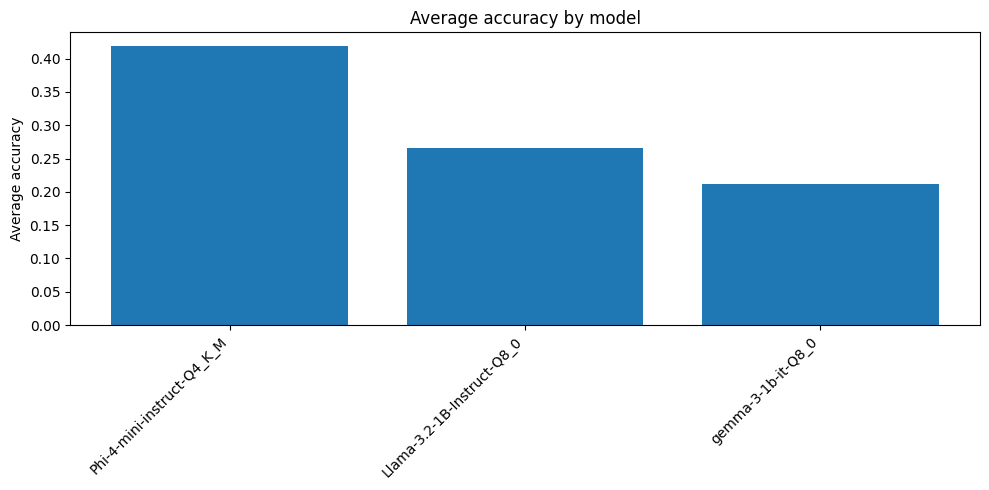

In [20]:
acc_plot = (
    scored.groupby("model", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 5))
plt.bar(acc_plot["model"], acc_plot["accuracy"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Average accuracy")
plt.title("Average accuracy by model")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "accuracy_by_model.png", dpi=200)
plt.show()


 Latency by model

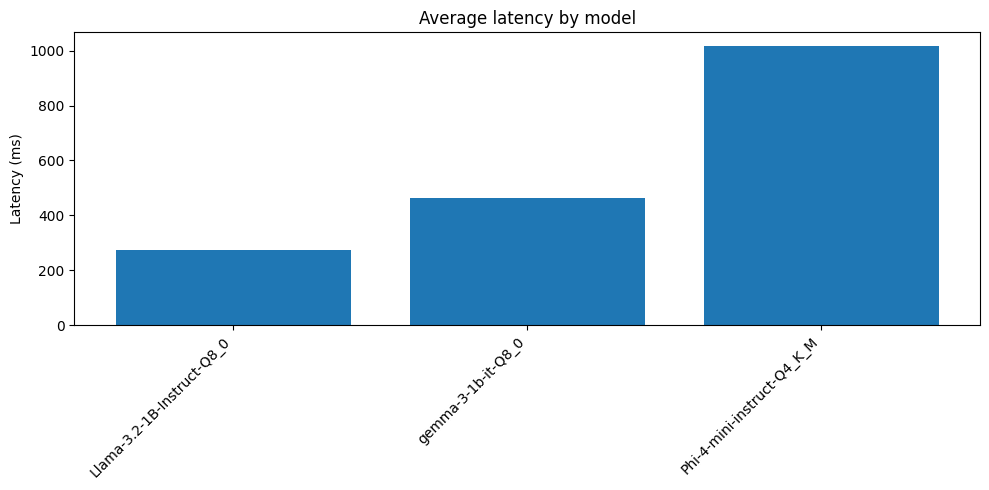

In [21]:
lat_plot = (
    scored.groupby("model", as_index=False)["latency"]
    .mean()
    .sort_values("latency", ascending=True)
)

plt.figure(figsize=(10, 5))
plt.bar(lat_plot["model"], lat_plot["latency"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Latency (ms)")
plt.title("Average latency by model")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "latency_by_model.png", dpi=200)
plt.show()


 Throughput by model

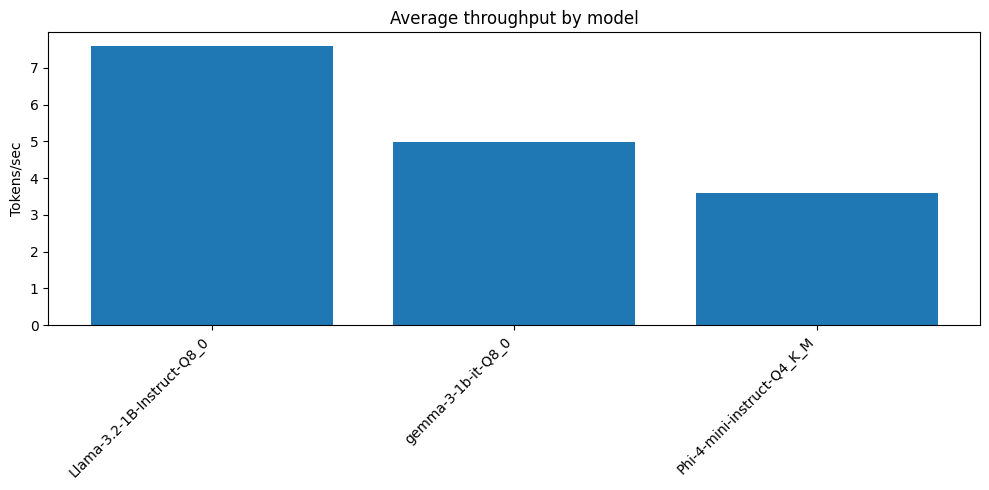

In [22]:
tps_plot = (
    summary.groupby("model", as_index=False)["tps"]
    .mean()
    .sort_values("tps", ascending=False)
)

plt.figure(figsize=(10, 5))
plt.bar(tps_plot["model"], tps_plot["tps"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Tokens/sec")
plt.title("Average throughput by model")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "throughput_by_model.png", dpi=200)
plt.show()


 RAM by model

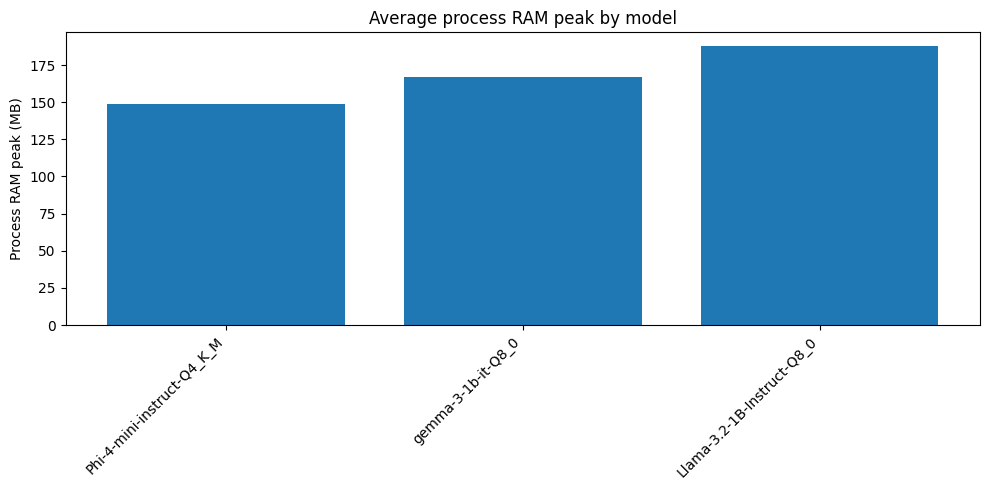

In [23]:
ram_plot = (
    summary.groupby("model", as_index=False)["ram"]
    .mean()
    .sort_values("ram", ascending=True)
)

plt.figure(figsize=(10, 5))
plt.bar(ram_plot["model"], ram_plot["ram"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Process RAM peak (MB)")
plt.title("Average process RAM peak by model")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "ram_by_model.png", dpi=200)
plt.show()


 Accuracy vs latency

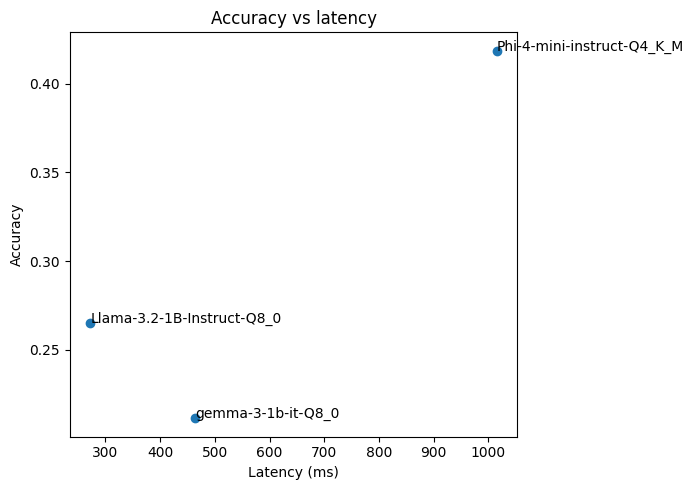

In [24]:
acc_lat = (
    scored.groupby("model", as_index=False)
    .agg({
        "accuracy": "mean",
        "latency": "mean"
    })
)

plt.figure(figsize=(7, 5))
plt.scatter(acc_lat["latency"], acc_lat["accuracy"])

for _, row in acc_lat.iterrows():
    plt.annotate(row["model"], (row["latency"], row["accuracy"]))

plt.xlabel("Latency (ms)")
plt.ylabel("Accuracy")
plt.title("Accuracy vs latency")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "accuracy_vs_latency.png", dpi=200)
plt.show()


 Throughput vs RAM

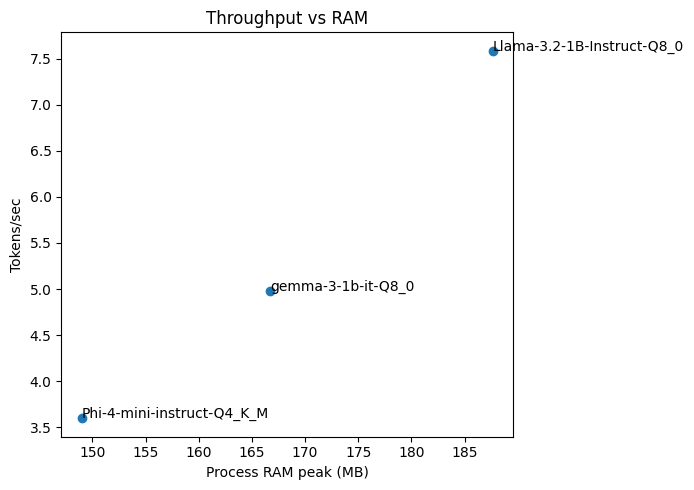

In [25]:
tps_ram = (
    summary.groupby("model", as_index=False)
    .agg({
        "tps": "mean",
        "ram": "mean"
    })
)

plt.figure(figsize=(7, 5))
plt.scatter(tps_ram["ram"], tps_ram["tps"])

for _, row in tps_ram.iterrows():
    plt.annotate(row["model"], (row["ram"], row["tps"]))

plt.xlabel("Process RAM peak (MB)")
plt.ylabel("Tokens/sec")
plt.title("Throughput vs RAM")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "throughput_vs_ram.png", dpi=200)
plt.show()


 Accuracy vs RAM

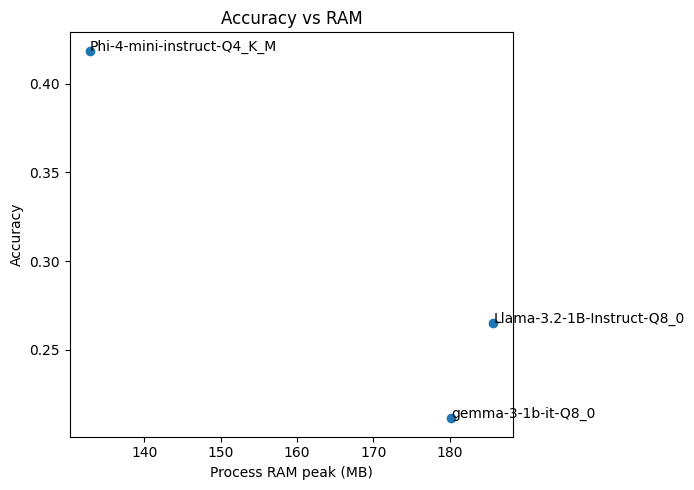

In [26]:
acc_ram = (
    scored.groupby("model", as_index=False)
    .agg({
        "accuracy": "mean",
        "ram": "mean"
    })
)

plt.figure(figsize=(7, 5))
plt.scatter(acc_ram["ram"], acc_ram["accuracy"])

for _, row in acc_ram.iterrows():
    plt.annotate(row["model"], (row["ram"], row["accuracy"]))

plt.xlabel("Process RAM peak (MB)")
plt.ylabel("Accuracy")
plt.title("Accuracy vs RAM")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "accuracy_vs_ram.png", dpi=200)
plt.show()


 Per-dataset accuracy

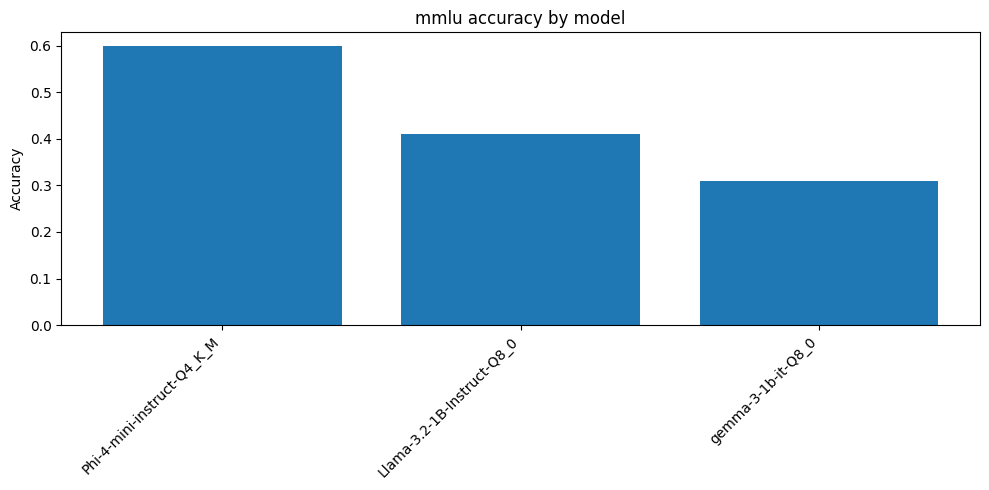

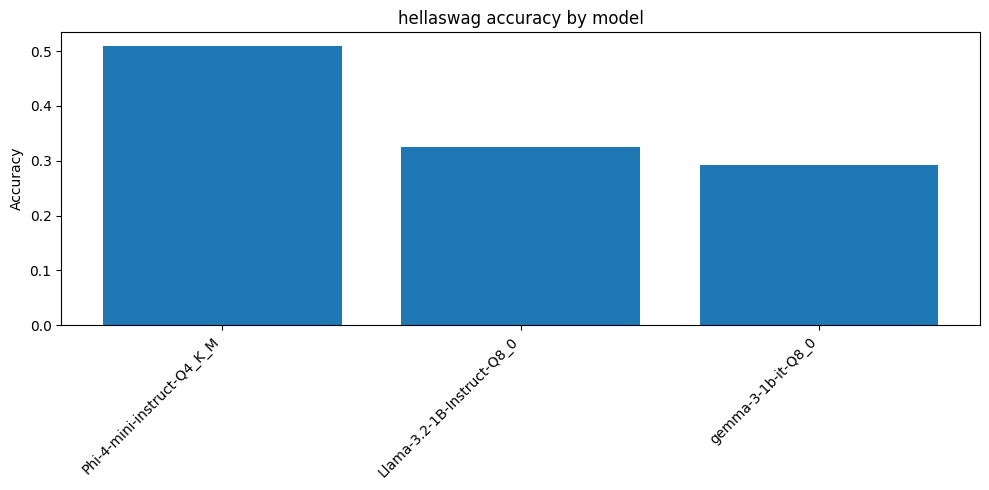

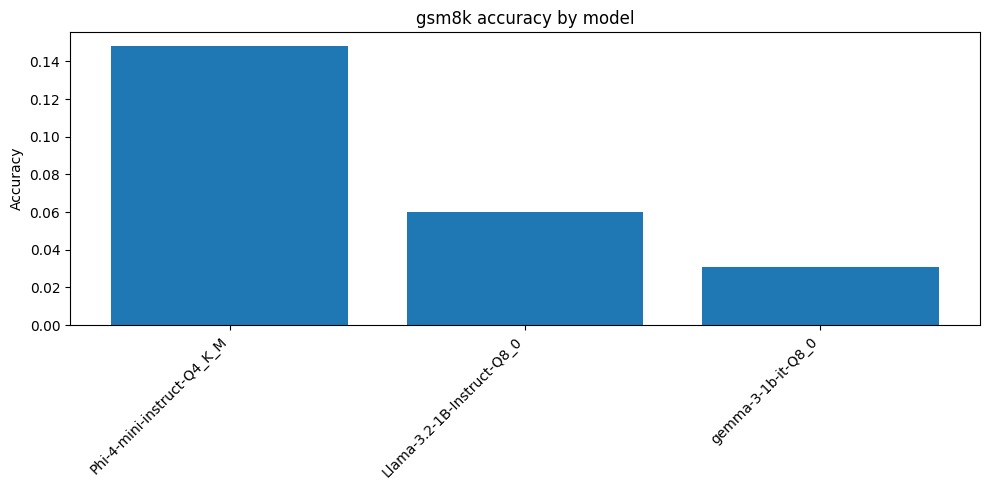

In [27]:
for ds in ["mmlu", "hellaswag", "gsm8k"]:
    sub = scored[scored["dataset"] == ds].groupby("model", as_index=False)["accuracy"].mean()
    sub = sub.sort_values("accuracy", ascending=False)

    plt.figure(figsize=(10, 5))
    plt.bar(sub["model"], sub["accuracy"])
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Accuracy")
    plt.title(f"{ds} accuracy by model")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{ds}_accuracy_by_model.png", dpi=200)
    plt.show()


 Per-dataset latency

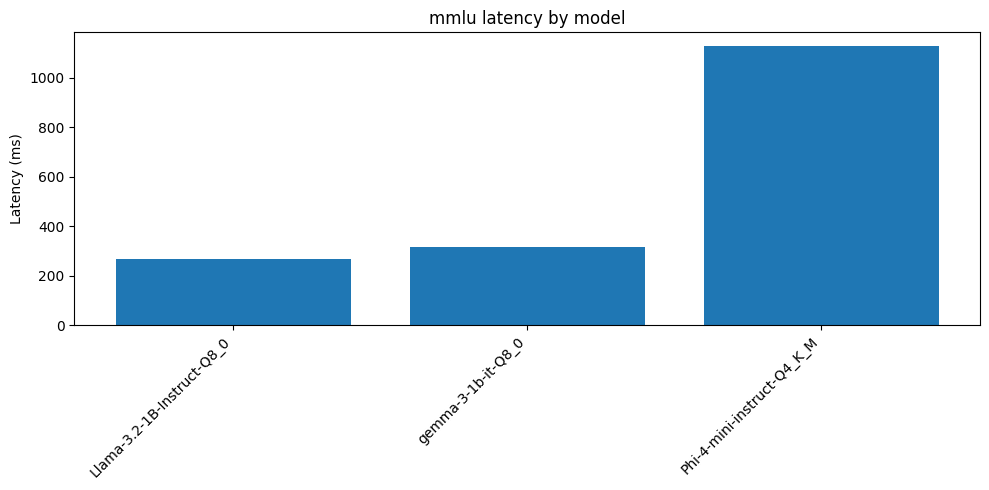

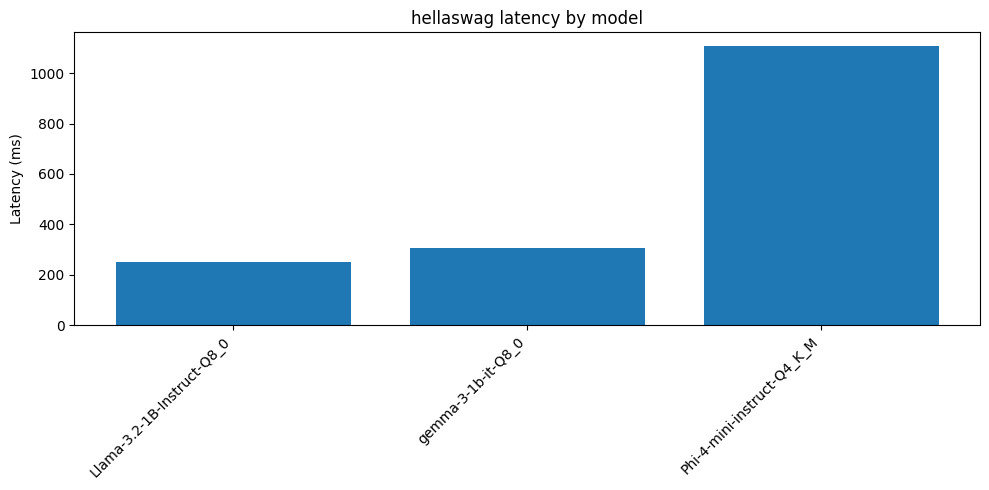

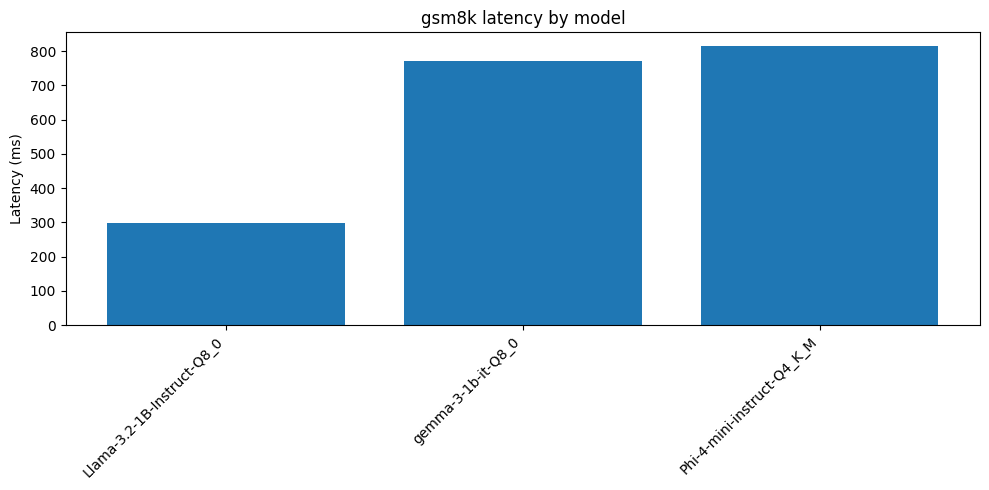

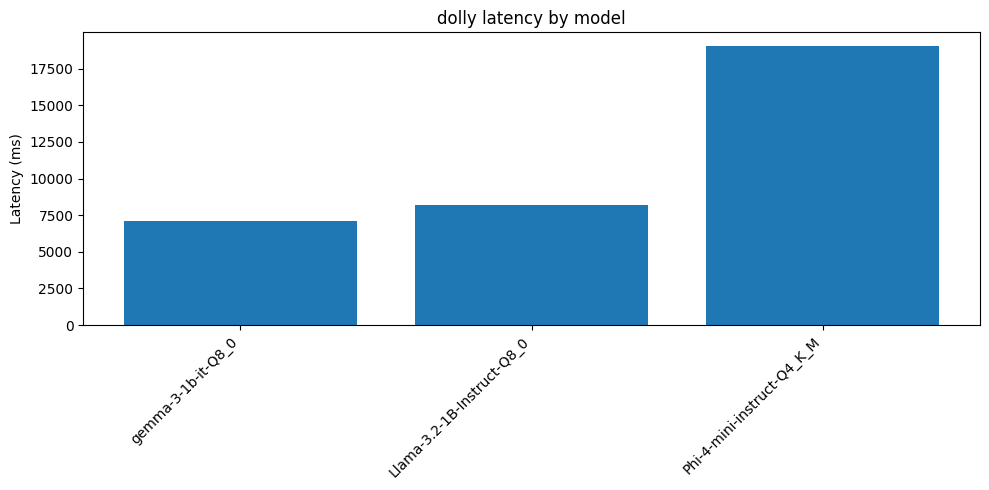

In [28]:
for ds in ["mmlu", "hellaswag", "gsm8k", "dolly"]:
    sub = summary[summary["dataset"] == ds].groupby("model", as_index=False)["latency"].mean()
    sub = sub.sort_values("latency", ascending=True)

    plt.figure(figsize=(10, 5))
    plt.bar(sub["model"], sub["latency"])
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Latency (ms)")
    plt.title(f"{ds} latency by model")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{ds}_latency_by_model.png", dpi=200)
    plt.show()


 Dolly throughput

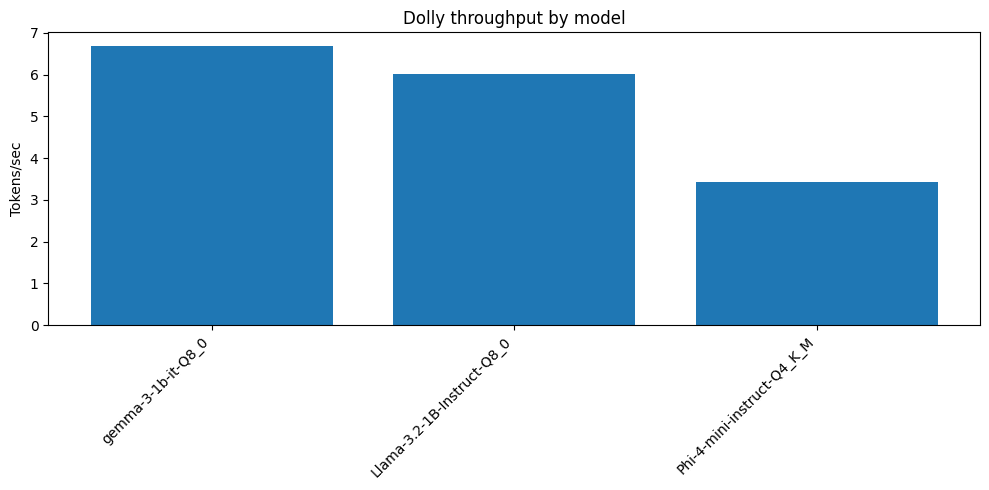

In [29]:
if not dolly.empty:
    dolly_tps = dolly.groupby("model", as_index=False)["tps"].mean().sort_values("tps", ascending=False)

    plt.figure(figsize=(10, 5))
    plt.bar(dolly_tps["model"], dolly_tps["tps"])
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Tokens/sec")
    plt.title("Dolly throughput by model")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "dolly_throughput_by_model.png", dpi=200)
    plt.show()
